# 06 — Variables explicatives sur la grille mondiale

**Objectif :** calculer les 12 variables candidates sur une grille mondiale, avec les mêmes sources et les mêmes définitions qu'à l'entraînement. Cette grille sert à étudier le comportement des modèles hors du domaine des données (`04_comparaison_modeles.ipynb`, partie C), puis à produire la carte de Q10 pour ORCHIDEE. Produit `data/grille_05deg.csv.gz`.

**Choix :**
- **grille régulière de 0.5° en latitude-longitude**, de 90° N à 60° S (Antarctique exclu), soit 300 × 720 cellules. C'est la résolution habituelle d'ORCHIDEE ; la grille exacte reste à confirmer avec B. Guenet ;
- **mêmes sources et mêmes périodes qu'à l'entraînement** : ERA5-Land 1995–2024 (climat et humidité du sol), SoilGrids 2.0 (sol), RESOLVE 2017 (végétation) ;
- **valeur d'une cellule = moyenne sur la cellule** (≈ 55 km). À l'entraînement, les valeurs étaient moyennées sur ≈ 15 km autour de chaque site : l'effet de ce changement d'échelle est mesuré à l'étape 6.

Chaque étape suit la structure : **Objectif** → **Raisonnement** → code → **Constat**.

In [1]:
# Imports : fichiers, données, rasters (rasterio), cartes vectorielles (geopandas), Google Earth Engine (ee)
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import ee
from rasterio.features import rasterize
from rasterio.transform import from_origin
from rasterio.warp import Resampling, reproject

In [2]:
# Dossier des fichiers externes (non versionné), connexion à Earth Engine
externe = Path("../data/externe")
ee.Initialize(project="crp-geosciences")

## Étape 1 — La grille

In [3]:
# Grille de 0.5° : 300 lignes (90° N → 60° S) × 720 colonnes (180° O → 180° E)
NLIG, NCOL, PAS = 300, 720, 0.5
transform = from_origin(-180, 90, PAS, PAS)

In [4]:
# Latitude et longitude du centre de chaque cellule
LAT, LON = np.meshgrid(90 - PAS / 2 - PAS * np.arange(NLIG), -180 + PAS / 2 + PAS * np.arange(NCOL), indexing="ij")

## Étape 2 — Climat et humidité du sol (ERA5-Land 1995–2024, via Earth Engine)

**Raisonnement :** même calcul qu'au notebook 03. Pour chaque mois de l'année, on fait la moyenne sur 30 ans, puis on agrège les pixels ERA5-Land de 0.1° en moyenne sur chaque cellule de 0.5°. Les cellules sans terre émergée sont marquées par une valeur sentinelle (−9999), puis mises à vide.

In [5]:
# Fonction : climatologie mensuelle 1995–2024 d'une variable ERA5-Land, moyennée par cellule de 0.5° → tableau (300, 720, 12)
def climatologie(variable):
    era5 = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR").filterDate("1995-01-01", "2025-01-01").select(variable)
    pile = ee.ImageCollection([era5.filter(ee.Filter.calendarRange(m, m, "month")).mean() for m in range(1, 13)]).toBands().toFloat()
    pile = pile.setDefaultProjection(era5.first().projection()).reduceResolution(ee.Reducer.mean(), maxPixels=1024).reproject(crs="EPSG:4326", crsTransform=list(transform)[:6])
    grille = {"dimensions": {"width": NCOL, "height": NLIG}, "affineTransform": {"scaleX": PAS, "shearX": 0, "translateX": -180, "shearY": 0, "scaleY": -PAS, "translateY": 90}, "crsCode": "EPSG:4326"}
    tab = ee.data.computePixels({"expression": pile.unmask(-9999), "fileFormat": "NUMPY_NDARRAY", "grid": grille})
    tab = np.stack([tab[n] for n in tab.dtype.names], axis=-1).astype(float)
    return np.where(tab == -9999, np.nan, tab)

In [6]:
# Climatologies mensuelles : température de l'air (K), précipitations (m/mois), humidité de la couche 0–7 cm (m³/m³) ; ≈ 2 min
temperature = climatologie("temperature_2m")
precipitations = climatologie("total_precipitation_sum")
humidite = climatologie("volumetric_soil_water_layer_1")

In [7]:
# Variables climatiques, définies comme à l'entraînement
MAT = temperature.mean(axis=2) - 273.15
MAP = precipitations.sum(axis=2) * 1000
SWC_mean = humidite.mean(axis=2)
chauds = np.argsort(temperature, axis=2)[..., -3:]
SWC_warm_rel = np.take_along_axis(humidite, chauds, axis=2).mean(axis=2) / SWC_mean

## Étape 3 — Sol (SoilGrids 2.0, version à 5 km)

**Raisonnement :** mêmes couches qu'à l'entraînement : pH 0–5 cm, et azote, argile, sable et carbone organique 5–15 cm. Chaque couche à 5 km (projection de Goode) est reprojetée sur la grille en moyenne par cellule, les pixels masqués (glace, eau) étant ignorés. Les unités sont converties comme dans le dataset : `N515` en mg/kg (cg/kg × 10), argile et sable en %, carbone organique en g/kg, pH divisé par 10.

In [8]:
# Téléchargement unique du pH à 5 km, s'il est absent (les autres couches ont été téléchargées par le notebook 03)
if not (externe / "phh2o_0-5cm_mean_5000.tif").exists():
    urlretrieve("https://files.isric.org/soilgrids/latest/data_aggregated/5000m/phh2o/phh2o_0-5cm_mean_5000.tif", externe / "phh2o_0-5cm_mean_5000.tif")

In [9]:
# Fonction : couche SoilGrids à 5 km, moyennée sur chaque cellule de la grille → tableau (300, 720)
def sol(fichier):
    sortie = np.full((NLIG, NCOL), np.nan)
    with rasterio.open(externe / fichier) as src:
        reproject(rasterio.band(src, 1), sortie, dst_transform=transform, dst_crs="EPSG:4326", dst_nodata=np.nan, resampling=Resampling.average)
    return sortie

In [10]:
# Variables de sol, dans les unités du dataset
pH = sol("phh2o_0-5cm_mean_5000.tif") / 10
azote = sol("nitrogen_5-15cm_mean_5000.tif")
N515 = azote * 10
clay = sol("clay_5-15cm_mean_5000.tif") / 10
sand = sol("sand_5-15cm_mean_5000.tif") / 10
SOC = sol("soc_5-15cm_mean_5000.tif") / 10
CN = SOC / (azote / 100)

## Étape 4 — Végétation (biomes RESOLVE → typologie)

**Raisonnement :** chaque cellule prend le biome du polygone RESOLVE qui contient son centre. Pour une cellule côtière dont le centre tombe en mer, on prend le polygone qui touche la cellule : sans cela, ≈ 7 400 cellules côtières (11 % des cellules ayant des données de sol) seraient perdues. On en déduit la classe de la typologie validée (`data/typologie_biomes.csv`, qui couvre les 14 biomes). Les cellules « N/A » (glaces, lacs) n'ont pas de classe.

In [11]:
# Polygones RESOLVE et numéro de leur biome
eco = gpd.read_file(externe / "Ecoregions2017.zip", columns=["BIOME_NAME"])
noms = sorted(eco.BIOME_NAME.unique())
formes = list(zip(eco.geometry, eco.BIOME_NAME.map(noms.index)))

In [12]:
# Biome de chaque cellule : polygone contenant le centre, sinon (cellule côtière) polygone touchant la cellule ; −1 si aucun
centre = rasterize(formes, out_shape=(NLIG, NCOL), transform=transform, fill=-1, dtype="int16")
touche = rasterize(formes, out_shape=(NLIG, NCOL), transform=transform, fill=-1, dtype="int16", all_touched=True)
codes = np.where(centre >= 0, centre, touche)

In [13]:
# Nom du biome et classe de la typologie de chaque cellule
biome = np.where(codes >= 0, np.array(noms)[codes], None)
typologie = pd.Series(biome.ravel()).map(pd.read_csv("../data/typologie_biomes.csv", index_col="biome").typologie)

## Étape 5 — Assemblage et sauvegarde

**Raisonnement :** une ligne par cellule. On garde les cellules où toutes les variables sont disponibles. L'index d'une ligne vaut ligne × 720 + colonne, ce qui permet de retrouver la cellule d'un site. La colonne `aire` (cosinus de la latitude) sert à pondérer les statistiques par la surface réelle des cellules.

In [14]:
# Tableau de toutes les cellules, avec les variables dans les unités et sous les noms du dataset
grille = pd.DataFrame({
    "lat": LAT.ravel(), "lon": LON.ravel(), "aire": np.cos(np.radians(LAT.ravel())),
    "MAT_public": MAT.ravel(), "MAP_public": MAP.ravel(), "pH_public": pH.ravel(), "N515": N515.ravel(),
    "clay": clay.ravel(), "sand": sand.ravel(), "CN": CN.ravel(), "SWC_mean": SWC_mean.ravel(), "SWC_warm_rel": SWC_warm_rel.ravel(),
    "biome": biome.ravel(), "typologie": typologie.values})

In [15]:
# Transformations log, comme dans la table de modélisation, puis cellules complètes uniquement
grille = grille.assign(logMAP=np.log(grille.MAP_public), logN515=np.log(grille.N515)).replace([np.inf, -np.inf], np.nan).dropna()
print(len(grille), "cellules complètes")

64745 cellules complètes


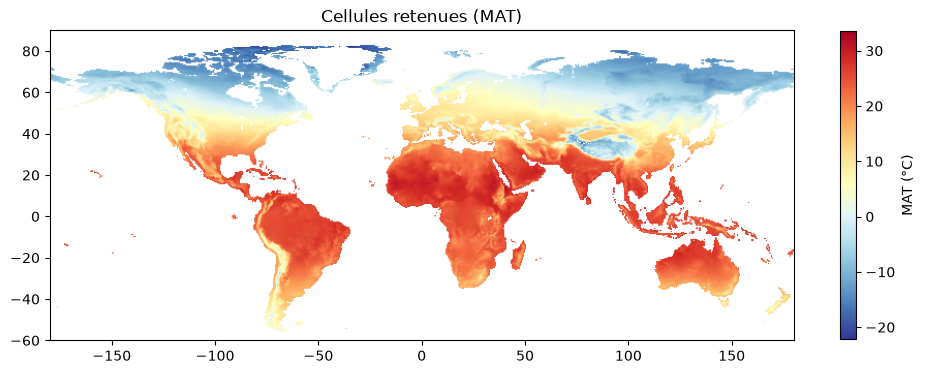

In [16]:
# Carte de contrôle : température moyenne annuelle des cellules retenues (cellules écartées en blanc)
carte = np.full(NLIG * NCOL, np.nan)
carte[grille.index] = grille.MAT_public
plt.figure(figsize=(12, 5))
plt.imshow(carte.reshape(NLIG, NCOL), extent=(-180, 180, -60, 90), cmap="RdYlBu_r")
plt.colorbar(label="MAT (°C)", shrink=0.8); plt.title("Cellules retenues (MAT)")
plt.show()

In [17]:
# Sauvegarde de la grille (avec son index : ligne × 720 + colonne)
grille.to_csv("../data/grille_05deg.csv.gz", index_label="cellule")

## Étape 6 — Validation aux sites : effet du changement d'échelle

**Objectif :** mesurer l'écart entre les valeurs de la grille (moyenne sur ≈ 55 km) et celles des sites (≈ 15 km), pour les variables utilisées par les modèles.

**Raisonnement :** pour chaque site, on lit la cellule de la grille qui le contient, puis on calcule la corrélation et l'écart médian entre les deux valeurs.

In [18]:
# Cellule de la grille de chaque site (index : ligne × 720 + colonne) ; vide si la cellule a été écartée
v4 = pd.read_csv("../data/dataset_v4.csv")
cellule = ((90 - v4.lat) // PAS).astype(int) * NCOL + ((v4.lon + 180) // PAS).astype(int)
aux_sites = grille.reindex(cellule.values).reset_index(drop=True)
print(aux_sites.lat.notna().sum(), "sites sur", len(v4), "ont une cellule complète")

131 sites sur 131 ont une cellule complète


In [19]:
# Pour chaque variable : corrélation entre valeur du site et valeur de sa cellule, et écart médian (cellule − site)
variables = ["MAT_public", "logMAP", "pH_public", "logN515", "clay", "sand", "CN", "SWC_mean", "SWC_warm_rel"]
pd.DataFrame({"corrélation": [v4[v].corr(aux_sites[v]) for v in variables], "écart médian": [(aux_sites[v] - v4[v]).median() for v in variables]}, index=variables).round(2)

,corrélation,écart médian
MAT_public,0.99,0.02
logMAP,0.98,0.01
pH_public,0.99,-0.00
logN515,0.96,-0.00
clay,0.96,0.30
sand,0.97,-0.32
CN,0.94,-0.08
SWC_mean,0.92,-0.00
SWC_warm_rel,0.98,0.00


In [20]:
# Typologie : part des sites dont la cellule a la même classe
print(f"{(aux_sites.typologie == v4.typologie)[aux_sites.lat.notna()].mean():.0%} des sites ont la même classe que leur cellule")

95% des sites ont la même classe que leur cellule


**Constat :**
- Les 131 sites ont une cellule complète. Les valeurs de la grille concordent très bien avec celles des sites : corrélations de 0.92 à 0.99, écarts médians quasi nuls (argile et sable : ± 0.3 point de %, négligeable). 95 % des sites ont la même classe de végétation que leur cellule.
- Passer d'une moyenne sur ≈ 15 km à une moyenne sur ≈ 55 km change donc peu les variables : un modèle entraîné sur les sites peut être appliqué à la grille.
- La grille compte 64 745 cellules. Sont écartées les glaces (Groenland), les lacs et les cellules sans données de sol.